# Method 1: Minutes shrinkage
Pull a low-minute per-90 toward the group average, trusting it more as minutes grow.

`estimate = w * low_minute_p90 + (1 - w) * group_mean`, with `w = minutes / (minutes + k)`.

- `k` is fit **per stat** by Normal maximum likelihood (`rate ~ N(mean, signal + noise / minutes)`, `k = noise / signal`) on the training prefixes, weighting each player-season equally (`reconstruct_methods.weighted_k`).
- `group_mean` is the minutes-weighted mean of the training low-minute rates.
- The weight depends only on the player's actual minutes, so it works for any amount of data.

**Setup shared by every method.** One model per gender and position group, trained on every per-game prefix (the player's first k matches, up to 750 minutes) of the 900+ minute player-seasons, each with its full-season per-90 as the target. The same fitted model handles any number of minutes. Rates, ratios and percents are never estimated: they are rebuilt from the estimated per-90 volumes.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


## 1. Results across all 14 gender / position-group sets

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

method,raw,shrink
checkpoint,,
250,1.489,0.817
500,0.713,0.618
750,0.518,0.524


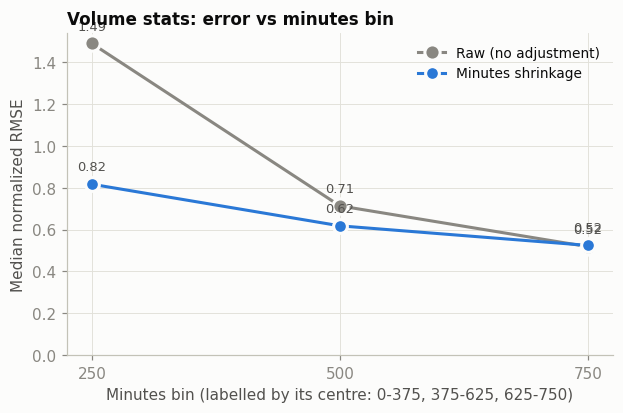

In [2]:
METHOD = "shrink"
METHODS = ["raw", METHOD]
summary = nh.median_nrmse(V, METHODS)
display(summary.round(3))
nh.curve_plot(summary, METHODS, "Volume stats: error vs minutes bin")
plt.show()

Error reduction versus raw (median over stats) and by position group:

method,shrink (% reduction)
minutes bin,
250,45.1
500,12.0
750,0.0


checkpoint,250,500,750
group,,,
Attacking Midfielders,41.5,9.6,-3.2
Center Backs,47.9,16.0,3.7
Center Forwards,44.2,10.6,-2.3
Central Midfielders,42.2,11.2,-0.4
GK,53.8,20.1,2.9
Outside Backs,45.7,12.7,1.9
Wingers,43.3,9.8,-4.1


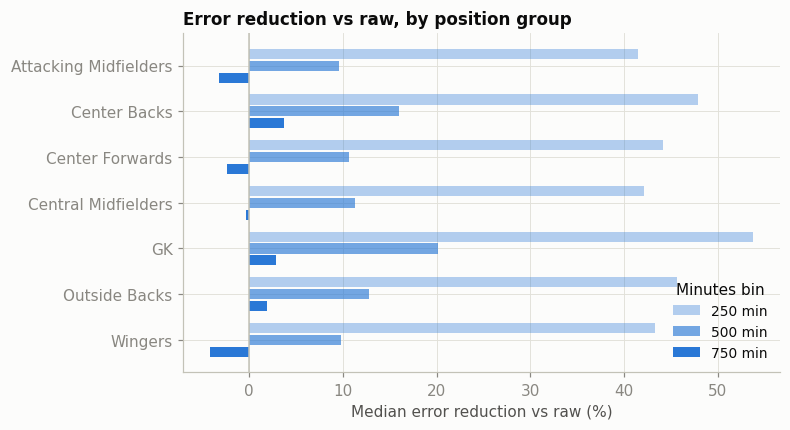

In [3]:
display(nh.improvement_table(V, [METHOD]).mul(100).round(1).rename_axis("minutes bin").add_suffix(" (% reduction)"))
by_group = nh.improvement_by_group(V, METHOD)
display(by_group.mul(100).round(1))
nh.group_bars(by_group, METHOD, "Error reduction vs raw, by position group")
plt.show()

Which stats improve most and least in the 500 bin?

In [4]:
best, worst = nh.per_stat(V, METHOD, 500)
display(pd.DataFrame({"most improved": best.mul(100).round(1)}))
display(pd.DataFrame({"least improved / worse": worst.mul(100).round(1)}))

,most improved
stat,
gk_clean_sheets,30.4
gk_conceded_goals,21.8
xa_minus_assists,21.5
second_assists,21.1
third_assists,21.1
goals_prevented,20.7
goals_minus_xg,20.5
dangerous_own_half_losses,19.9


,least improved / worse
stat,
field_aerial_duels_won,1.0
field_aerial_duels,1.8
aerial_duels_won,2.1
aerial_duels,2.3
duels,5.4
offensive_duels,5.8
free_kicks,6.4
long_passes,6.4


### Rates rebuilt from the estimated volumes
Percents, ratios and shares are **not** estimated directly. They are recomputed from the estimated per-90 volumes with the repo formulas (`rate_rebuild.py`). A rate is compared only where both the truth and the estimate exist; the share of rates the estimate could not produce is reported separately.

In [5]:
display(nh.median_nrmse(R, METHODS).round(3).rename_axis("minutes bin"))
display(nh.rate_table(R, METHODS, cp=500).round(3))
display(nh.missing_table(R, METHODS).round(4))

method,raw,shrink
minutes bin,,
250,1.737,0.911
500,0.838,0.721
750,0.610,0.606


method,raw,shrink
stat_type,,
rate_api_approx,0.844,0.681
rate_api_exact,1.031,0.875
rate_derived,0.754,0.637


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
shrink,17532604,139671,17392933,0.0080


## 2. Worked example: male Wingers (live run)
This re-runs the method out-of-fold on one group so every step below is reproducible here (the full results above came from `reconstruction_eval.py`).

raw     median nrmse @250/500/750: [1.378, 0.627, 0.451]
shrink  median nrmse @250/500/750: [0.777, 0.56, 0.459]


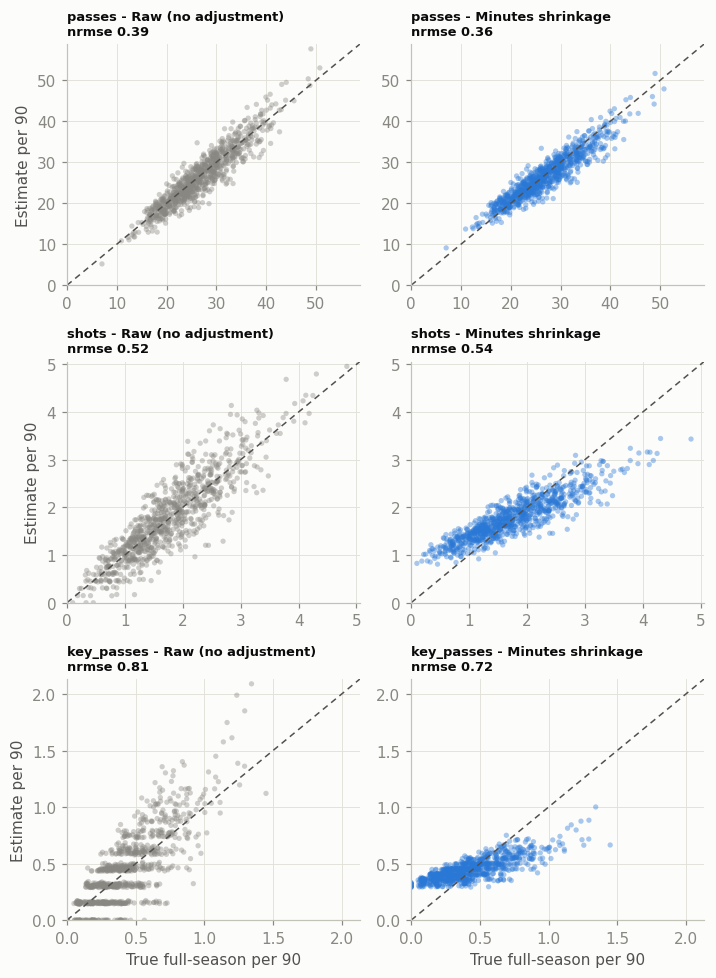

In [6]:
pool, stems, est = nh.demo_group("male", "Wingers", ["raw", METHOD])
for m in ["raw", METHOD]:
    print(f"{m:7s} median nrmse @250/500/750:",
          [round(float(nh.nrmse_per_stat(pool, est[m], b).median()), 3) for b in (250, 500, 750)])
fig = nh.scatter_grid(pool, est, ["passes", "shots", "key_passes"], 500, ["raw", METHOD])
plt.show()

### Diagnostic: how strongly is each stat shrunk?
`k` is the minutes at which the player's own data and the group average get equal weight. Large `k` = a noisy stat that needs many minutes before the player's own value is trusted. (Fitted here on all of this group's prefixes: descriptive, not a validation score.)

In [7]:
low = rm.get_low(pool, stems)
k = pd.Series({s: rm.weighted_k(low[s], pool["actual_minutes"], pool["weight"])[0] for s in stems})
weights = pd.DataFrame({f"w @{m} min": m / (m + k) for m in (250, 500, 750)})
weights.insert(0, "k (minutes)", k)
display(weights.sort_values("k (minutes)").round(2).iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]])
print("Share of stats with k > 500 minutes:", round(float((k > 500).mean()), 2))

,k (minutes),w @250 min,w @500 min,w @750 min
free_kicks,6.590000e+01,0.79,0.88,0.92
corners,9.131000e+01,0.73,0.85,0.89
successful_passes,1.057800e+02,0.70,0.83,0.88
offensive_duels,1.082700e+02,0.70,0.82,0.87
dribbles,1.176800e+02,0.68,0.81,0.86
direct_red_cards,1.405057e+16,0.00,0.00,0.00
card_weight,2.010011e+16,0.00,0.00,0.00
goals_minus_xg,4.459928e+16,0.00,0.00,0.00
red_cards,7.011815e+16,0.00,0.00,0.00
third_assists,1.382584e+17,0.00,0.00,0.00


Share of stats with k > 500 minutes: 0.41


### Strengths and limits
- One number per stat, no tuning, and it keeps the player's own signal when minutes are high.
- Every stat is shrunk on its own, so it ignores that stats move together (a player with many shots probably has many touches in the box).
- It shrinks toward the *low-minute* mean, not the high-minute population mean.